In [1]:
import numpy as np
import pandas as pd
import cv2
from matplotlib import pyplot as plt
from numpy.linalg import inv
import os

from colormath.color_conversions import convert_color
from colormath.color_objects import LabColor, XYZColor
from colormath.color_diff import delta_e_cie2000

from skimage.color import rgb2lab, lab2rgb

from scipy.interpolate import BSpline, make_interp_spline

from scipy.optimize import minimize
from scipy.optimize import dual_annealing
from scipy.optimize import least_squares
from scipy.optimize import basinhopping

from numpy.random import random
from numpy.random import rand

# Spectrum Transfer Model

In [2]:
st_extend_20 = 0
st_extend_21 = 1
st_extend_30 = 2

class SpectrumTransfer:
    
    def __init__(self):
        self.extend_mode = 0
        self.pca_eigenvectors = None
        self.pca_mean = None
        self.M = None
        self.TransM = None
        self.TransMin = 0.0
        self.TransMax = 1.0
        
    def get_extend_color(self, src_rgb):
        
        extend = None

        if self.extend_mode == 0:
            extend = np.array([np.ones(src_rgb[:,0].shape), src_rgb[:,0], src_rgb[:,1], src_rgb[:,2], np.power(src_rgb[:,0],2), np.power(src_rgb[:,1],2), np.power(src_rgb[:,2],2)])
        elif self.extend_mode == 1:
            extend = np.array([np.ones(src_rgb[:,0].shape), src_rgb[:,0], src_rgb[:,1], src_rgb[:,2], np.power(src_rgb[:,0],2), np.power(src_rgb[:,1],2), np.power(src_rgb[:,2],2),src_rgb[:,0]* src_rgb[:,1],src_rgb[:,0]* src_rgb[:,2],src_rgb[:,1]* src_rgb[:,2]])
        elif self.extend_mode == 2:
            extend = np.array([np.ones(src_rgb[:,0].shape), src_rgb[:,0], src_rgb[:,1], src_rgb[:,2], np.power(src_rgb[:,0],2), np.power(src_rgb[:,1],2), np.power(src_rgb[:,2],2),src_rgb[:,0]* src_rgb[:,1],src_rgb[:,0]* src_rgb[:,2],src_rgb[:,1]* src_rgb[:,2], np.power(src_rgb[:,0],3), np.power(src_rgb[:,1],3), np.power(src_rgb[:,2],3)])

        return extend
    
    def prepare(self):
        self.TransM = np.dot(self.M.T, self.pca_eigenvectors)
        return
     
    def train(self, extend_mode, train_spec, train_color, pca_comps=6):
        self.extend_mode = extend_mode
        
        pca = PCA(n_components=pca_comps, whiten=False)
        pca.fit(train_spec)
        
        self.pca_eigenvectors = pca.components_
        self.pca_mean = pca.mean_

        trans_pca_a = pca.transform(train_spec)
        trans_extend_c = self.get_extend_color(train_color)

        self.M = np.dot(trans_pca_a.T, pinv(trans_extend_c))

        self.prepare()
        
        c = np.arange(256)
        all_color = np.array(np.meshgrid(c, c, c)).T.reshape(-1,3)

        self.TransMin = 0.0
        self.TransMax = 1.0
        
#         min_v = 100.0
#         max_v = -100.0

#         split_num = 64
#         batch_size = int(all_color.shape[0] / split_num)

#         for n in range(64):
#             test_c = all_color[n * batch_size: (n+1) *batch_size, :]
#             test_s = self.transfer(test_c)
#             batch_min = np.min(test_s)
#             batch_max = np.max(test_s)

#             min_v = min(min_v, batch_min)
#             max_v = max(max_v, batch_max)

#         self.TransMin = min_v
#         self.TransMax = max_v
        
        return
    
    def save(self, setup_file):
        np.savez(setup_file, a=self.M, b=self.pca_eigenvectors, c=self.pca_mean, d=np.array([self.TransMin,self.TransMax]), e=np.array([self.extend_mode]))

        
    def save_files(self, setup_path):
        
        if not os.path.exists(setup_path):
            os.mkdir(setup_path, 0o666)
        
        np.save(os.path.join(setup_path, "spec_a.npy"), self.M)
        np.save(os.path.join(setup_path, "spec_b.npy"), self.pca_eigenvectors)
        np.save(os.path.join(setup_path, "spec_c.npy"), self.pca_mean)
        np.save(os.path.join(setup_path, "spec_d.npy"), np.array([self.TransMin,self.TransMax]))
        np.save(os.path.join(setup_path, "spec_e.npy"), np.array([self.extend_mode]))

    def save_txts(self, setup_path):
        
        if not os.path.exists(setup_path):
            os.mkdir(setup_path, 0o666)
        
        np.savetxt(os.path.join(setup_path, "spec_a.txt"), self.M)
        np.savetxt(os.path.join(setup_path, "spec_b.txt"), self.pca_eigenvectors)
        np.savetxt(os.path.join(setup_path, "spec_c.txt"), self.pca_mean)
        np.savetxt(os.path.join(setup_path, "spec_d.txt"), np.array([self.TransMin,self.TransMax]))
        np.savetxt(os.path.join(setup_path, "spec_e.txt"), np.array([self.extend_mode]))
        
    def load(self, setup_file):
        weight = np.load(setup_file)
        
        self.M = weight["a"]
        self.pca_eigenvectors = weight["b"]
        self.pca_mean = weight["c"]
        
#         self.TransMin = weight['d'][0]
#         self.TransMax = weight['d'][1]
        
        self.extend_mode = weight['e'][0]
        
        self.prepare()
        
        return
 
    def transfer1D(self, src_data):
        
        src_data = src_data.astype(np.float32)

        tar_sepc = np.dot(self.get_extend_color(src_data).T, self.TransM) + self.pca_mean
        
        tar_sepc = (tar_sepc - self.TransMin) / (self.TransMax - self.TransMin)

        return tar_sepc
    
    def transfer(self, src_data):
        
        src_data = src_data.astype(np.float32)
        
        src_shape = src_data.shape

        if len(src_shape) >= 3:
            src_data = src_data.reshape(-1, src_shape[-1])

        tar_sepc = np.dot(self.get_extend_color(src_data).T, self.TransM) + self.pca_mean

        if len(src_shape) >= 3:
            tar_sepc = tar_sepc.reshape(src_shape[0:-1] + tuple([self.pca_mean.shape[0]]))
        
        tar_sepc = (tar_sepc - self.TransMin) / (self.TransMax - self.TransMin)
        
        return tar_sepc

# Color Reproduce Model

In [3]:
class ColorReproducer:
    
    def __init__(self): 
        self.light_spec = None
        self.cmf = None
        self.ma = None
        self.d65 = np.array([0.95047, 1.00000000, 1.08883])
        self.is_ignore_ca = False
        
        self.light_spec_x3 = None
        self.cal_fact = None
        self.k = None
        self.white_light_k = None
        
    def prepare(self):
        self.light_spec_x3 = np.array([self.light_spec,self.light_spec,self.light_spec]).T 
        self.cal_fact = self.cmf * self.light_spec_x3
        self.k = 100.0 / sum(self.cal_fact[:,1])
        self.white_light_k = np.dot(self.cmf.T, self.light_spec) * (self.k / 100.0)
        self.cal_fact = self.cal_fact * self.k
 
        return

    def load(self, setup_path):
        self.light_spec = np.loadtxt(os.path.join(setup_path, 'CR_light.txt'))
        self.cmf = np.loadtxt(os.path.join(setup_path, 'CR_cmf.txt'))
        self.ma = np.loadtxt(os.path.join(setup_path, 'CR_ma.txt'))
        
        self.prepare()
        return
        
    def reproduce(self, img_spec, gain = 1.0, is_normalize = False, filter_band = None):
        
        dims = len(img_spec.shape)
        
        if dims == 2:
            hw,c = img_spec.shape
        elif dims == 3:
            h,w,c = img_spec.shape
        
        img_spec = img_spec.reshape((-1,c));
        
        fact = None
        
        if self.is_ignore_ca:
            fact = self.cal_fact
        else:
            fact = inv(self.ma).dot(np.diag(self.ma.dot(self.d65) / self.ma.dot(self.white_light_k))).dot(self.ma)
            fact = fact.dot(self.cal_fact.T).T 
            
        op_ref_spec = None
        
        if filter_band is not None:

            filter_band_set = filter_band - 380

            mask = np.zeros((w*h, 401))
            
            mask[:,filter_band_set] = 1

            op_ref_spec = img_spec * mask * gain

        else:

            op_ref_spec = img_spec * gain
        
        
        if is_normalize: 
            
            img_rep_xyz = op_ref_spec.dot(fact)

            min_v = img_rep_xyz.min()
            max_v = img_rep_xyz.max()

            img_rep_xyz = (img_rep_xyz - min_v) / (max_v - min_v) * 255.0
            
        else:
            
            img_rep_xyz = op_ref_spec.dot(fact) / 100.0 * 255.0
        
#         print('min', np.min(img_rep_xyz))
#         print('max', np.max(img_rep_xyz))
        
        img_rep_xyz.reshape(-1, 3)
        m = np.array([[3.2404542, -1.5371385, -0.4985314], [-0.9692660,  1.8760108,  0.0415560], [ 0.0556434, -0.2040259,  1.0572252]])
#         m = np.array([[0.4124564,0.3575761,  0.1804375], [0.2126729,  0.7151522,  0.0721750], [0.0193339,  0.1191920,  0.9503041]])
        m = m.T

        img_rep_rgb = np.dot(img_rep_xyz, m)
        
        img_rep_rgb[img_rep_rgb<0] = 0
        img_rep_rgb[img_rep_rgb>255] = 255
        img_rep_rgb = img_rep_rgb.astype('uint8')
        
        if dims == 2:
            img_rep_rgb = img_rep_rgb.reshape(hw, 3)
        elif dims == 3:
            img_rep_rgb = img_rep_rgb.reshape(h, w, 3)

#         if dims == 2:
#             img_rep_xyz = img_rep_xyz.reshape(hw, 1, 3).astype('uint8')
#         elif dims == 3:
#             img_rep_xyz = img_rep_xyz.reshape(h, w, 3).astype('uint8')
            
#         img_rep_rgb = cv2.cvtColor(img_rep_xyz, cv2.COLOR_XYZ2RGB)
        
#         if dims == 2:
#             img_rep_rgb = img_rep_rgb.reshape(hw, 3)
            
        return img_rep_rgb

In [4]:
# transfer = SpectrumTransfer()
# transfer.load("weight.npz")

# reproducer = ColorReproducer()
# reproducer.load('cr_weights')

# wlis = np.load('data_wli.npy')

# wli_spec = transfer.transfer1D(wlis)


# sim_wlis = reproducer.reproduce(wli_spec, 2.0, False, None)

# errs = cal_delta_e_cie2000_rgb(wlis, sim_wlis)

# Functions

In [5]:
def cal_delta_e_cie2000_lab(lab_src, lab_test):
    
    errs = np.zeros(lab_src.shape[0])
    
    for i in range(lab_src.shape[0]):
        
        color0 = LabColor(lab_l=lab_src[i,0], lab_a=lab_src[i,1], lab_b=lab_src[i,2])
        color1 = LabColor(lab_l=lab_test[i,0], lab_a=lab_test[i,1], lab_b=lab_test[i,2])

        errs[i] = delta_e_cie2000(color0, color1)
        
    return errs

def cal_delta_e_cie2000_rgb(rgb_src, rgb_test):
    
    lab_src = rgb2lab(rgb_src)
    lab_test = rgb2lab(rgb_test)
    
    errs = np.zeros(lab_src.shape[0])
    
    for i in range(lab_src.shape[0]):
        
        color0 = LabColor(lab_l=lab_src[i,0], lab_a=lab_src[i,1], lab_b=lab_src[i,2])
        color1 = LabColor(lab_l=lab_test[i,0], lab_a=lab_test[i,1], lab_b=lab_test[i,2])

        errs[i] = delta_e_cie2000(color0, color1)
    
    # ignore gray
#     return errs[:-6]

    return errs

def rmse(errs):
    return np.sqrt(((errs) ** 2).mean())

In [6]:
def plot_diff(rgb1, rgb2):
    
    rgb1 = rgb1.astype('uint8')
    rgb2 = rgb2.astype('uint8')
    
    errs = cal_delta_e_cie2000_rgb(rgb1, rgb2)
    
    plt.figure(figsize=(4, 14))
    plt.axis('off')
    plt.xlim(0, 30)
    plt.ylim(-2, 26)

    plt.annotate('c1.', (8, 25), fontsize = 20)
    plt.annotate('c2.', (16, 25), fontsize = 20)
    plt.annotate('CIEDE2000', (24, 25), fontsize = 20)

    plt.annotate('mean', (16, -1), fontsize = 20)
    plt.annotate('%.2f' %(np.mean(errs)), (26, -1), fontsize = 20)

    plt.annotate('rmse', (16, -2), fontsize = 20)
    plt.annotate('%.2f' %(rmse(errs)), (26, -2), fontsize = 20)
    
    for i in range(24):

        now_c1 = rgb1[i,:]
        now_c2 = rgb2[i,:]

        plt.scatter([10], [24 - i], marker='s', s = 500, color = (now_c1[0]/255, now_c1[1]/255, now_c1[2]/255))
        plt.scatter([18], [24 - i], marker='s', s = 500, color = (now_c2[0]/255, now_c2[1]/255, now_c2[2]/255))

        plt.annotate('%.2f' %(errs[i]), (26, 24 - i - 0.2), fontsize = 20)

    plt.show()

# Initial data

In [7]:
# standard data
# 24 std, wli, nbi color

std24 = np.load('data_std.npy')
wlis = np.load('data_wli.npy')
nbis = np.load('data_nbi.npy')

nbis_sim1 = np.load('data_nbi_sim1.npy')
nbis_sim2 = np.load('data_nbi_sim2.npy')
nbis_sim3 = np.load('data_nbi_sim3.npy')

caps1 = np.load('data_cap1.npy')
caps2 = np.load('data_cap3.npy')
caps3 = np.load('data_cap5.npy')

caps_trans1 = np.load('data_cap1_nbi.npy')
caps_trans2 = np.load('data_cap3_2_nbi.npy')
caps_trans3 = np.load('data_cap5_nbi.npy')

In [8]:
from_color = caps2
to_color = caps_trans2

In [9]:
# initial SpectrumTransfer and ColorReproducer

transfer = SpectrumTransfer()
transfer.load("weight.npz")

reproducer = ColorReproducer()
reproducer.load('cr_weights')

In [10]:
# system lighting
light_d65 = np.loadtxt(r'lights\D65.txt').T

# olympus lighting
light_wli = np.loadtxt('Light_WLI.txt').T
light_nbi = np.loadtxt('Light_NBI.txt').T

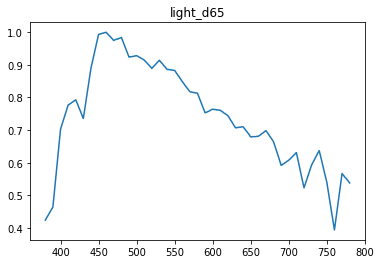

In [11]:
plt.title('light_d65')
plt.plot(np.arange(380,781), light_d65)
plt.show()

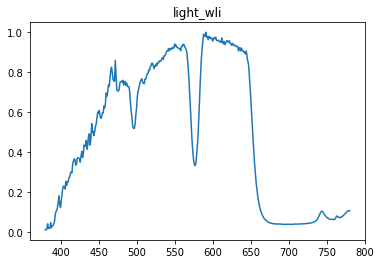

In [12]:
plt.title('light_wli')
plt.plot(np.arange(380,781), light_wli)
plt.show()

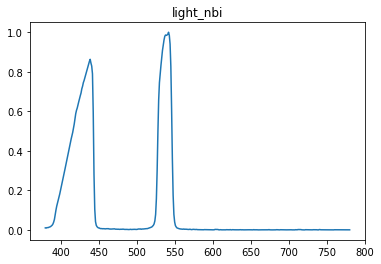

In [13]:
plt.title('light_nbi')
plt.plot(np.arange(380,781), light_nbi)
plt.show()

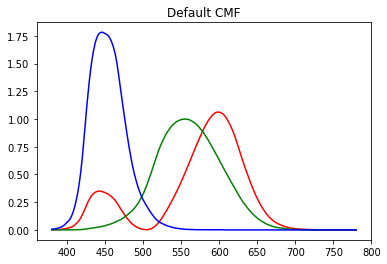

In [14]:
plt.title('Default CMF')
plt.plot(np.arange(380,781), reproducer.cmf[:,0], 'r')
plt.plot(np.arange(380,781), reproducer.cmf[:,1], 'g')
plt.plot(np.arange(380,781), reproducer.cmf[:,2], 'b')
plt.show()

In [15]:
# transfer wli to spectrum

from_spec = transfer.transfer1D(from_color)

rmse 29.994468820820355


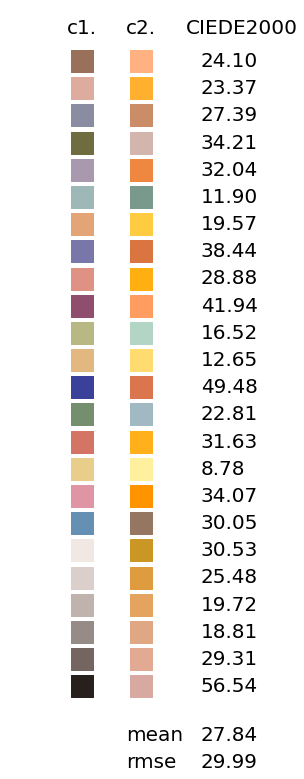

In [17]:
# set lighting
reproducer.light_spec = light_d65
# reproducer.light_spec = light_wli
reproducer.prepare()

# simulate wli from spectrum
sim_color = reproducer.reproduce(from_spec, 1.0, False, None)

errs = cal_delta_e_cie2000_rgb(from_color, sim_color)

print('rmse', rmse(errs))

plot_diff(from_color, sim_color)

# Optimize Gain (base on WLI reproduce)

In [17]:
# Optimize Gain

def objective(gain):
     
    sim_color = reproducer.reproduce(from_spec, gain, False, None)

    errs = cal_delta_e_cie2000_rgb(from_color, sim_color)

    return rmse(errs)

# define range for input
r_min, r_max = 0.0, 5.0

v0 = rand(1) * 2
bounds = [[r_min, r_max]]
result = dual_annealing(objective, bounds, x0 = v0)

# v0 = rand(1) * 2
# result = basinhopping(objective, v0)

# summarize the result
print('Status : %s' % result['message'])
print('Total Evaluations: %d' % result['nfev'])

# evaluate solution
solution = result['x']
evaluation = objective(solution)

print('solution', solution)
print('rmse', evaluation)

Status : ['Maximum number of iteration reached']
Total Evaluations: 2021
solution [1.94311263]
rmse 11.675174123268103


In [18]:
# update

best_gain = solution[0]

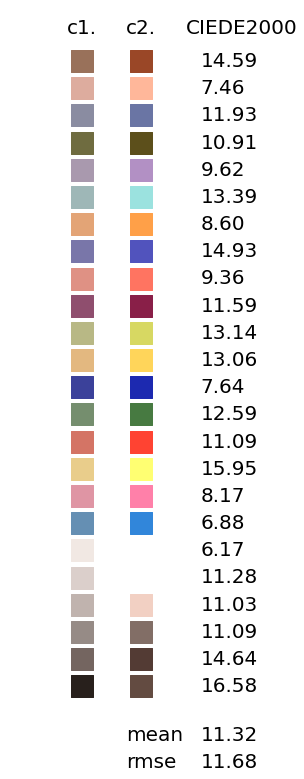

In [19]:
sim_color = reproducer.reproduce(from_spec, best_gain, False, None)

plot_diff(from_color, sim_color)

# Optimize CMF (base on WLI reproduce)
- adjust full CMF

In [20]:
cmf_gap = 40

def interp_cmf(cmf_with_gap):

    cmf_with_gap = np.array(cmf_with_gap)
    cmf_with_gap = cmf_with_gap.reshape(-1,3)
    
    if cmf_gap == 1:
        return cmf_with_gap
    
    x = np.arange(380,781,cmf_gap)
    
    xvals = np.arange(380,781)
    
    cmf_1um = np.zeros((401, 3))
    
    for i in range(3):
        
        spl = make_interp_spline(x, cmf_with_gap[:,i])
        cmf_1um[:,i] = spl(xvals).T
        
#         cmf_1um[:,i] = np.interp(xvals, x, cmf_with_gap[:,i])  
    
    return cmf_1um

def objective(cmf_with_gap):
    
    reproducer.cmf = interp_cmf(cmf_with_gap)
    reproducer.prepare()
    
    sim_wlis = reproducer.reproduce(from_spec, best_gain, False, None)

    errs = cal_delta_e_cie2000_rgb(wlis, sim_wlis)

    return rmse(errs)

# define range for input
r_min, r_max = 0.0, 2.0

v0 = rand((int(400 / cmf_gap + 1)) * 3) * 2
bounds = [[r_min, r_max]] * (int(400 / cmf_gap + 1)) * 3
result = dual_annealing(objective, bounds, x0=v0)

# v0 = rand((int(400 / cmf_gap + 1)) * 3) * 2
# result = basinhopping(objective, v0)

# summarize the result
print('Status : %s' % result['message'])
print('Total Evaluations: %d' % result['nfev'])

# evaluate solution
solution = result['x']
evaluation = objective(solution)

print('rmse', evaluation)

Status : ['Maximum number of iteration reached']
Total Evaluations: 73311
rmse 17.41013096014372


In [21]:
# update

reproducer.cmf = interp_cmf(solution)
reproducer.prepare()

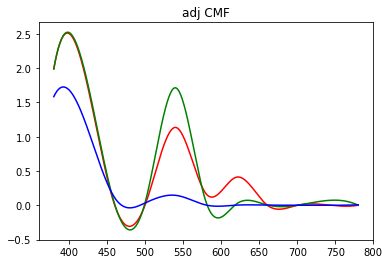

In [22]:
plt.title('adj CMF')
plt.plot(np.arange(380,781), reproducer.cmf[:,0], 'r')
plt.plot(np.arange(380,781), reproducer.cmf[:,1], 'g')
plt.plot(np.arange(380,781), reproducer.cmf[:,2], 'b')
plt.show()

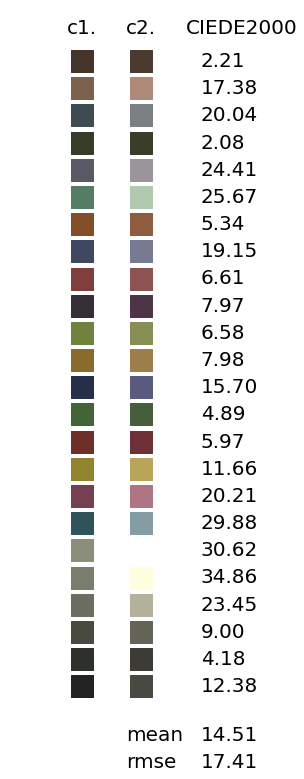

In [23]:
sim_wlis = reproducer.reproduce(from_spec, best_gain, False, None)

plot_diff(wlis, sim_wlis)

# Optimize CMF (base on WLI reproduce)
- only adjust CMF ratio

In [24]:
base_cmf = reproducer.cmf

def objective(cmf_ratio):
    
    tar_cmf = base_cmf.copy()
    
    for i in range(3):
        tar_cmf[:,i] = base_cmf[:,i] * cmf_ratio[i]
    
    reproducer.cmf = tar_cmf
    reproducer.prepare()
    
    sim_wli = reproducer.reproduce(from_spec, best_gain, False, None)

    errs = cal_delta_e_cie2000_rgb(wlis, sim_wli)

    return rmse(errs)

# define range for input
r_min, r_max = 0.1, 2.0

bounds = [[r_min, r_max]] * 3
result = dual_annealing(objective, bounds)

# summarize the result
print('Status : %s' % result['message'])
print('Total Evaluations: %d' % result['nfev'])

# evaluate solution
solution = result['x']
evaluation = objective(solution)

print('solution', solution)
print('rmse', evaluation)

Status : ['Maximum number of iteration reached']
Total Evaluations: 6033
solution [1.77357713 1.77649766 1.73169465]
rmse 17.409478733261473


In [25]:
# update

best_cmf_ratio = solution
tar_cmf = base_cmf.copy()

for i in range(3):
    tar_cmf[:,i] = base_cmf[:,i] * best_cmf_ratio[i]
    
reproducer.cmf = tar_cmf
reproducer.prepare()

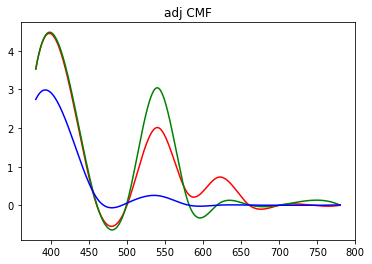

In [26]:
plt.title('adj CMF')
plt.plot(np.arange(380,781), reproducer.cmf[:,0], 'r')
plt.plot(np.arange(380,781), reproducer.cmf[:,1], 'g')
plt.plot(np.arange(380,781), reproducer.cmf[:,2], 'b')
plt.show()

# transfer real image

In [27]:
# img = cv2.imread('tar_wli_avg.bmp')
img = cv2.imread('en_img.jpg')

img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

spec = transfer.transfer(img);

rep_img = reproducer.reproduce(spec, best_gain, False, None)

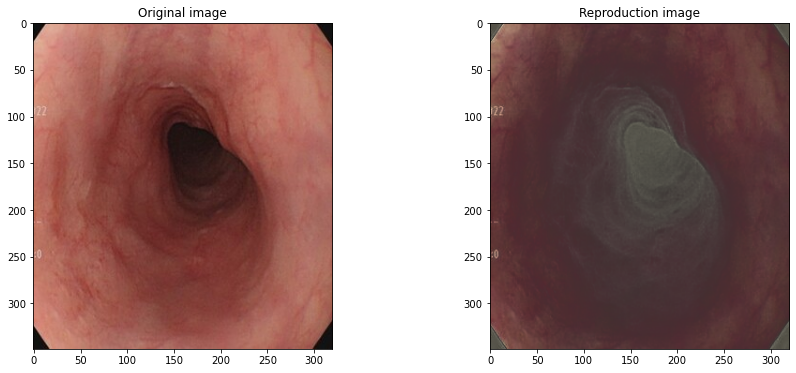

In [28]:
plt.figure(figsize=(15, 6))

plt.subplot(1,2,1)
plt.imshow(img)
plt.title('Original image')

plt.subplot(1,2,2)
plt.imshow(rep_img)
plt.title('Reproduction image')

plt.show()

# Optimize NBI (base on WLI to NBI)
- Lighting

In [29]:
# if use 401 band, will take long time Optimize
# set light gap, avoid use to many variable
# set light_gap = 1, 401 variables
# set light_gap = 10, 41 variables
# set light_gap = 40, 11 variables

light_gap = 10

def interp_light(light_spec_gap):
    
    if light_gap == 1:
        return light_spec_gap
    
    x = np.arange(380,781,light_gap)
    
    xvals = np.arange(380,781)
    
    spl = make_interp_spline(x, light_spec_gap)
    light_spec_1nm = spl(xvals).T
    
#     light_spec_1nm = np.interp(xvals, x, light_spec_gap)  
    
    return light_spec_1nm

def objective(light_spec_gap):
    
    # update lighting and prepare
    reproducer.light_spec = interp_light(light_spec_gap)
    reproducer.prepare()
    
    sim_color = reproducer.reproduce(from_spec, best_gain, False, None)

    errs = cal_delta_e_cie2000_rgb(to_color, sim_color)

    return rmse(errs)
 
# define range for input
r_min, r_max = 0.0, 10.0
# define the starting point as a random sample from the domain
# pt = r_min + rand(401) * (r_max - r_min)

# perform the l-bfgs-b algorithm search
# result = minimize(objective, pt, method='Nelder-Mead')
# result = minimize(objective, pt, method='Newton-CG')
# result = minimize(objective, pt, method='Powell')
# result = minimize(objective, pt, method='BFGS')

v0 = r_min + rand(int(400 / light_gap + 1)) * (r_max - r_min)
bounds = [[r_min, r_max]] * (int(400 / light_gap + 1))
result = dual_annealing(objective, bounds, x0 = v0)

# summarize the result
print('Status : %s' % result['message'])
print('Total Evaluations: %d' % result['nfev'])
# evaluate solution
solution = result['x']
evaluation = objective(solution)

print('rmse', evaluation)

Status : ['Maximum number of iteration reached']
Total Evaluations: 87587
rmse 18.822254230943503


In [30]:
# update

reproducer.light_spec = interp_light(solution)
reproducer.prepare()

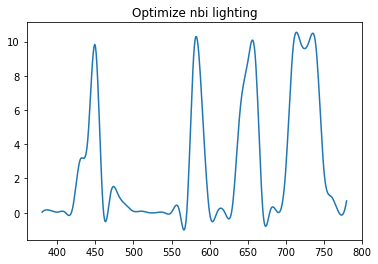

In [31]:
plt.title('Optimize nbi lighting')
plt.plot(np.arange(380,781), reproducer.light_spec)
plt.show()

In [32]:
np.save("data_nbi_sim_light2.npy", reproducer.light_spec)
np.savetxt('data_nbi_sim_light2.txt', reproducer.light_spec)

rmse 22.11703005519439


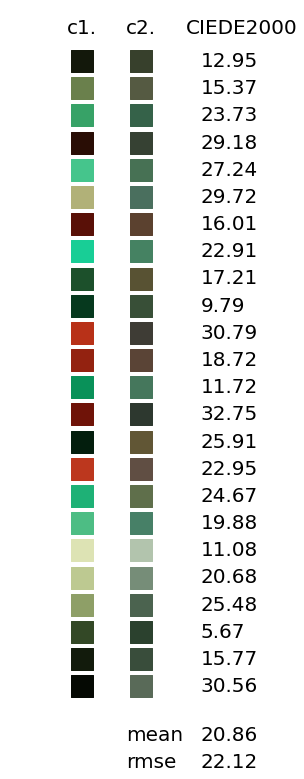

In [85]:
sim_color = reproducer.reproduce(from_spec, best_gain, False, None)

errs = cal_delta_e_cie2000_rgb(to_color, sim_color)

print('rmse',rmse(errs))

plot_diff(to_color, sim_color)

# Optimize NBI
- CMF

In [29]:
cmf_gap = 40

def interp_cmf(cmf_with_gap):

    cmf_with_gap = np.array(cmf_with_gap)
    cmf_with_gap = cmf_with_gap.reshape(-1,3)
    
    if cmf_gap == 1:
        return cmf_with_gap
    
    x = np.arange(380,781,cmf_gap)
    
    xvals = np.arange(380,781)
    
    cmf_1um = np.zeros((401, 3))
    
    for i in range(3):
        
        spl = make_interp_spline(x, cmf_with_gap[:,i])
        cmf_1um[:,i] = spl(xvals).T
        
#         cmf_1um[:,i] = np.interp(xvals, x, cmf_with_gap[:,i])  
    
    return cmf_1um

def objective(cmf_with_gap):
    
    reproducer.cmf = interp_cmf(cmf_with_gap)
    reproducer.prepare()
    
    sim_nbi = reproducer.reproduce(wli_spec, best_gain, False, None)

    errs = cal_delta_e_cie2000_rgb(nbis, sim_nbi)

    return rmse(errs)

# define range for input
r_min, r_max = 0.0, 2.0

v0 = rand((int(400 / cmf_gap + 1)) * 3) * 2
bounds = [[r_min, r_max]] * (int(400 / cmf_gap + 1)) * 3
result = dual_annealing(objective, bounds, x0=v0)

# v0 = rand((int(400 / cmf_gap + 1)) * 3) * 2
# result = basinhopping(objective, v0)

# summarize the result
print('Status : %s' % result['message'])
print('Total Evaluations: %d' % result['nfev'])

# evaluate solution
solution = result['x']
evaluation = objective(solution)

print('rmse', evaluation)

Status : ['Maximum number of iteration reached']
Total Evaluations: 67667
rmse 13.740952961531178


In [30]:
# update

reproducer.cmf = interp_cmf(solution)
reproducer.prepare()

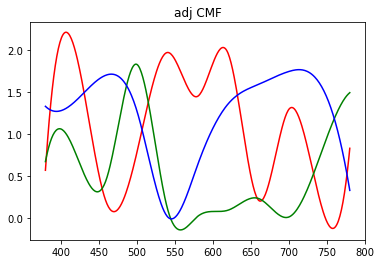

In [31]:
plt.title('adj CMF')
plt.plot(np.arange(380,781), reproducer.cmf[:,0], 'r')
plt.plot(np.arange(380,781), reproducer.cmf[:,1], 'g')
plt.plot(np.arange(380,781), reproducer.cmf[:,2], 'b')
plt.show()

rmse 13.740952961531178


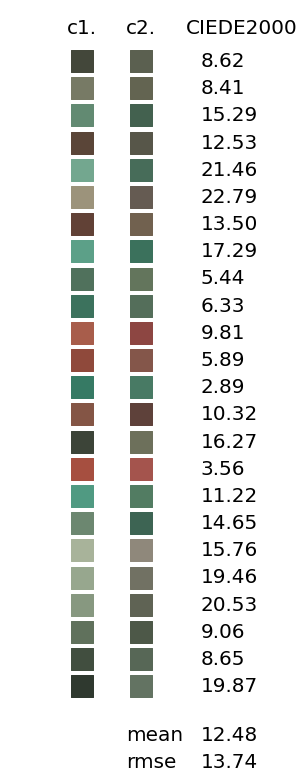

In [32]:
sim_nbis = reproducer.reproduce(wli_spec, best_gain, False, None)

errs = cal_delta_e_cie2000_rgb(nbis, sim_nbis)

print('rmse',rmse(errs))

plot_diff(nbis, sim_nbis)

# transfer real image

In [33]:
from os import listdir
from os.path import isfile, join

tar_path = 'en_imgs'

onlyfiles = [join(tar_path, f) for f in listdir(tar_path) if isfile(join(tar_path, f))]

imgs = [cv2.imread(file) for file in onlyfiles]
imgs = [cv2.cvtColor(img, cv2.COLOR_BGR2RGB) for img in imgs]

In [34]:
img = cv2.imread('en_img.jpg')
# img = cv2.imread('tar_wli_avg.bmp')
img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

# img = imgs[5]

spec = transfer.transfer(img);

rep_img = reproducer.reproduce(spec, best_gain, False, None)

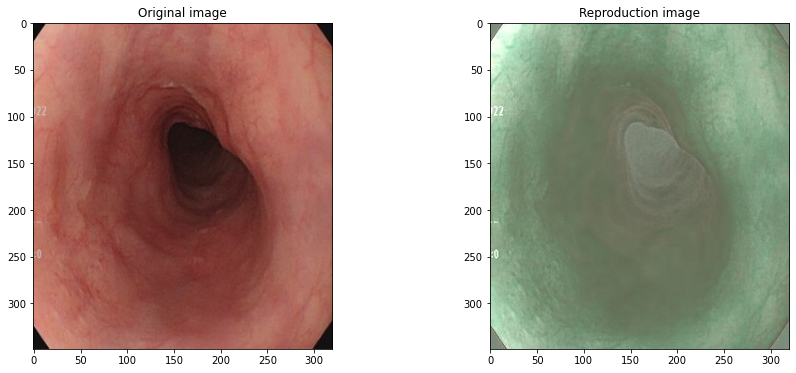

In [35]:
plt.figure(figsize=(15, 6))

plt.subplot(1,2,1)
plt.imshow(img)
plt.title('Original image')

plt.subplot(1,2,2)
plt.imshow(rep_img)
plt.title('Reproduction image')

plt.show()

In [36]:
# img = cv2.imread('en_img.jpg')
real_wli = cv2.imread('tar_wli_avg.bmp')

real_wli = cv2.cvtColor(real_wli, cv2.COLOR_BGR2RGB)

spec = transfer.transfer(real_wli);

rep_nbi = reproducer.reproduce(spec, best_gain, False, None)

In [37]:
real_nbi = cv2.imread('tar_nbi_avg.bmp')
real_nbi = cv2.cvtColor(real_nbi, cv2.COLOR_BGR2RGB)

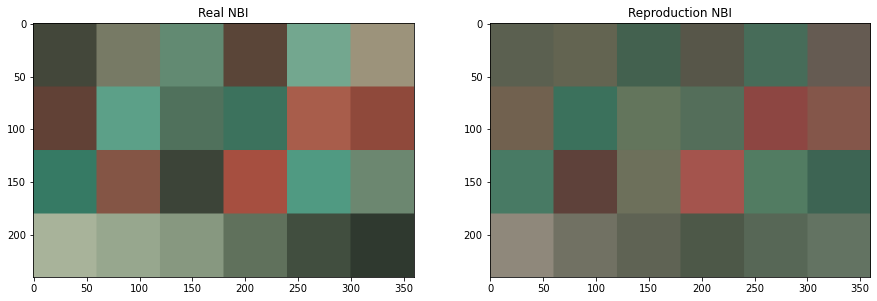

In [38]:
plt.figure(figsize=(15, 6))

plt.subplot(1,2,1)
plt.imshow(real_nbi)
plt.title('Real NBI')

plt.subplot(1,2,2)
plt.imshow(rep_nbi)
plt.title('Reproduction NBI')

plt.show()

In [39]:
def objective(m):
    
    sim_nbis = np.dot(wlis, m.reshape(3,3))
    
    sim_nbis[sim_nbis<0] = 0
    sim_nbis[sim_nbis>255] = 255
    sim_nbis = sim_nbis.astype('uint8')
  
    errs = cal_delta_e_cie2000_rgb(nbis, sim_nbis)

    return rmse(errs)

# define range for input
r_min, r_max = 0.0, 1.0

v0 = rand(9)
bounds = [[r_min, r_max]] * 9
result = dual_annealing(objective, bounds, x0=v0)

# v0 = rand((int(400 / cmf_gap + 1)) * 3) * 2
# result = basinhopping(objective, v0)

# summarize the result
print('Status : %s' % result['message'])
print('Total Evaluations: %d' % result['nfev'])

# evaluate solution
solution = result['x']
evaluation = objective(solution)

print('rmse', evaluation)

Status : ['Maximum number of iteration reached']
Total Evaluations: 18901
rmse 8.056985094037378


In [40]:
nbi_m = solution.reshape(3,3)

rmse 8.056985094037378


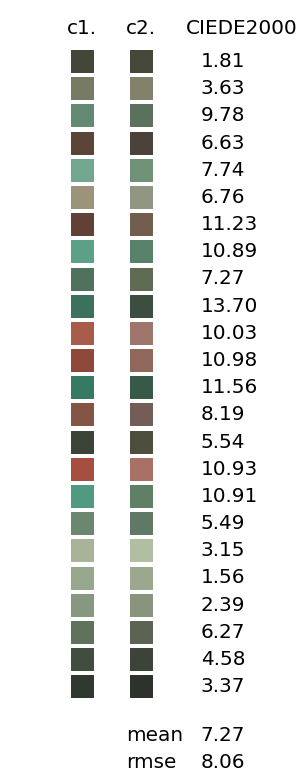

In [41]:

sim_nbis = np.dot(wlis, nbi_m)
sim_nbis[sim_nbis>255] = 255
sim_nbis[sim_nbis<0] = 0
sim_nbis = sim_nbis.astype('uint8')

errs = cal_delta_e_cie2000_rgb(nbis, sim_nbis)

print('rmse',rmse(errs))

plot_diff(nbis, sim_nbis)

In [42]:
img = cv2.imread('en_img.jpg')
# img = cv2.imread('tar_wli_avg.bmp')
img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

h,w,c = img.shape

rep_img = img.reshape(-1,c)
rep_img = np.dot(rep_img, nbi_m)
rep_img[rep_img>255] = 255
rep_img[rep_img<0] = 0
rep_img = rep_img.astype('uint8')
rep_img = rep_img.reshape(h,w,c)

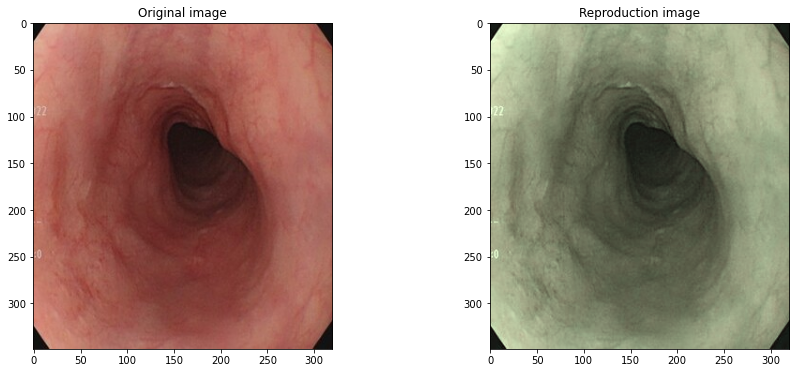

In [43]:
plt.figure(figsize=(15, 6))

plt.subplot(1,2,1)
plt.imshow(img)
plt.title('Original image')

plt.subplot(1,2,2)
plt.imshow(rep_img)
plt.title('Reproduction image')

plt.show()

# transfer data to txt

In [ ]:
sim_light1 = np.load('data_nbi_sim_light1.npy')
sim_light2 = np.load('data_nbi_sim_light2.npy')
sim_light3 = np.load('data_nbi_sim_light3.npy')

np.savetxt('data_nbi_sim_light1.txt', sim_light1)
np.savetxt('data_nbi_sim_light2.txt', sim_light2)
np.savetxt('data_nbi_sim_light3.txt', sim_light3)

# Test Functions

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

x = np.arange(380,781,10)
y = np.random.rand(41)

xvals = np.arange(380,781)
yinterp = np.interp(xvals, x, y)

plt.plot(x, y, 'o')
plt.plot(xvals, yinterp, '-x')
plt.show()

In [20]:
a = np.zeros((401, 3))

In [21]:
a.shape

(401, 3)